# 03 · Quantum Gates and Operations

**Covers:** unitary operations, the Hadamard gate, phase shifters, the Mach–Zehnder interferometer, the CNOT gate, and photonic beam splitters as unitaries.
**Photonics thread:** in a lossless chip every element is a unitary matrix. Beam splitter = Hadamard-like gate, phase shifter = phase gate, MZI = tunable beam splitter.

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

In [2]:
zero, one = qt.basis(2, 0), qt.basis(2, 1)            # H / V, or path 0 / path 1
Had = qt.Qobj([[1, 1], [1, -1]]) / np.sqrt(2)
P = qt.Qobj([[1, 0], [0, 0]])                         # polarizer (lossy)

def phase(phi):
    return qt.Qobj([[1, 0], [0, np.exp(1j * phi)]])

def is_unitary(U):
    return float(np.allclose((U.dag() * U).full(), np.eye(U.shape[0])))

## 1. Unitary = nothing gets lost

**Plain words:** a rotation keeps every distance; a unitary keeps the total probability at 1. The test is $U^\dagger U = I$.

- The swap $X$ and the Hadamard rearrange amplitudes: unitary.
- A polarizer absorbs part of the photon: (0.6, 0.8) becomes (0.6, 0), total probability 0.36. Not unitary.

**Gap:** real chips have loss, so real devices are never perfectly unitary. Loss is modelled in notebook 05.

**One sentence:** a unitary gate rearranges the state without losing probability, like a lossless optical element.

In [3]:
check("Hadamard is unitary", is_unitary(Had), 1.0)
check("X is unitary", is_unitary(qt.sigmax()), 1.0)
check("phase shifter is unitary", is_unitary(phase(0.7)), 1.0)
check("polarizer is NOT unitary", is_unitary(P), 0.0)

PASS  Hadamard is unitary: simulation = 1.0000, theory = 1.0000
PASS  X is unitary: simulation = 1.0000, theory = 1.0000
PASS  phase shifter is unitary: simulation = 1.0000, theory = 1.0000
PASS  polarizer is NOT unitary: simulation = 0.0000, theory = 0.0000


## 2. Hadamard: a 50:50 beam splitter

**Plain words:** the Hadamard turns horizontal into 45° and vertical into 135°. Optically it is a half-wave plate at 22.5°; in path encoding it is a 50:50 beam splitter. Applying it twice undoes it.

**Gap:** textbooks put the beam splitter's minus sign in different places. Only relative phases matter, so all conventions give the same physics.

**One sentence:** Hadamard turns a definite answer into a 50/50 split.

In [4]:
out = Had * zero
print((out.full().real).round(3).flatten())
check("P(path 0) after one splitter", abs(zero.dag() * out) ** 2, 0.5)
check("Had * Had = identity", float(np.allclose((Had * Had).full(), np.eye(2))), 1.0)

[0.707 0.707]
PASS  P(path 0) after one splitter: simulation = 0.5000, theory = 0.5000
PASS  Had * Had = identity: simulation = 1.0000, theory = 1.0000


## 3. Phase shifter and the Mach–Zehnder interferometer

**Plain words:** a phase shifter delays one path. Alone it is invisible, because probability only sees an amplitude's size, $|e^{i\varphi}|^2 = 1$. A second beam splitter makes the two paths meet and interfere, turning the hidden phase into a click probability:

$$\text{MZI} = H\,\Phi(\varphi)\,H,\qquad P(\text{output }0) = \cos^2(\varphi/2)$$

Same fringe as the classical MZI you simulate in Lumerical, but now one photon at a time.

**Gap:** each photon still lands in one detector; the fringe only appears after many photons.

**One sentence:** a phase shifter is invisible alone, and a beam splitter after it turns phase into probability.

In [5]:
check("phase alone leaves P(path 0)", abs(zero.dag() * phase(1.2) * out) ** 2, 0.5)
phis = np.linspace(0, 2 * np.pi, 9)
for phi in phis[[0, 2, 4]]:
    mzi_out = Had * phase(phi) * Had * zero
    check(f"MZI fringe at phi = {phi:.3f}", abs(zero.dag() * mzi_out) ** 2, np.cos(phi / 2) ** 2)

PASS  phase alone leaves P(path 0): simulation = 0.5000, theory = 0.5000
PASS  MZI fringe at phi = 0.000: simulation = 1.0000, theory = 1.0000
PASS  MZI fringe at phi = 1.571: simulation = 0.5000, theory = 0.5000
PASS  MZI fringe at phi = 3.142: simulation = 0.0000, theory = 0.0000


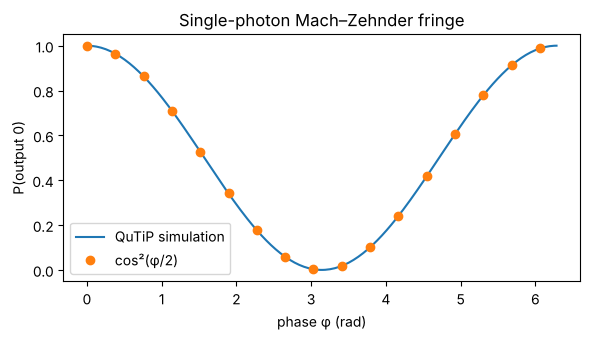

In [6]:
import matplotlib.pyplot as plt
grid = np.linspace(0, 2 * np.pi, 200)
sim = [abs(zero.dag() * Had * phase(f) * Had * zero) ** 2 for f in grid]
plt.figure(figsize=(6, 3.5))
plt.plot(grid, sim, label="QuTiP simulation")
plt.plot(grid[::12], np.cos(grid[::12] / 2) ** 2, "o", label="cos²(φ/2)")
plt.xlabel("phase φ (rad)"); plt.ylabel("P(output 0)"); plt.title("Single-photon Mach–Zehnder fringe")
plt.legend(); plt.tight_layout(); plt.show()

## 4. Two-qubit gate: CNOT

**Plain words:** CNOT flips the target qubit if the control is 1. It is the gate that creates entanglement (notebook 04). In linear optics a CNOT cannot be built deterministically from beam splitters alone; it needs extra photons and measurements, which is part of why photonic quantum computing is hard.

**One sentence:** CNOT is a 4×4 unitary that flips one qubit conditioned on another.

In [7]:
CNOT = qt.Qobj([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dims=[[2, 2], [2, 2]])
check("CNOT is unitary", is_unitary(CNOT), 1.0)
check("CNOT |10> = |11>", abs(qt.tensor(one, one).dag() * CNOT * qt.tensor(one, zero)) ** 2, 1.0)

PASS  CNOT is unitary: simulation = 1.0000, theory = 1.0000
PASS  CNOT |10> = |11>: simulation = 1.0000, theory = 1.0000


## 5. The waveguide beam splitter as a unitary

**Plain words:** a directional coupler mixes the photon-adding operators of two waveguides. Its unitary is $U(\theta) = \exp[\theta(a^\dagger b - a b^\dagger)]$, with transmission $T = \cos^2\theta$. For one photon this reproduces the 2×2 picture above; notebook 06 uses it for two photons.

**One sentence:** a coupler of length-dependent strength θ is a beam splitter with $T = \cos^2\theta$.

In [8]:
N = 3
A = qt.tensor(qt.destroy(N), qt.qeye(N))
B = qt.tensor(qt.qeye(N), qt.destroy(N))
def coupler(theta):
    return (theta * (A.dag() * B - A * B.dag())).expm()
single = qt.tensor(qt.basis(N, 1), qt.basis(N, 0))        # one photon in waveguide a
for theta in [np.pi / 8, np.pi / 4, np.pi / 3]:
    stays = abs(single.dag() * coupler(theta) * single) ** 2
    check(f"T = cos^2(theta) at theta = {theta:.3f}", stays, np.cos(theta) ** 2)

PASS  T = cos^2(theta) at theta = 0.393: simulation = 0.8536, theory = 0.8536
PASS  T = cos^2(theta) at theta = 0.785: simulation = 0.5000, theory = 0.5000
PASS  T = cos^2(theta) at theta = 1.047: simulation = 0.2500, theory = 0.2500


## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [9]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

15 of 15 checks passed
